<a href="https://colab.research.google.com/github/Luna0414/-DSC_110-/blob/main/Week_6/Data_summarization_10_13_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
#pyp is short for python

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/nhanes_final.csv')
#df short for data frame

In [6]:
df.head()
#missing data can be replaced with a 0 or NaN
#transform back to its original category names

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN


Transforming Variables

In [7]:
df['education'].unique()
#NaN is short for no applicable number

array([ 5.,  3., nan,  2.,  4.,  1.,  9.])

In [8]:
education_map = {
    1:'less than 9th grade',
    2:'9-11th grade',
    3:'high school grad',
    4:'some college or AA degree',
    5:'college grad',
    9:'do not know'
                 }

In [12]:
df['education_label'] = df['education'].map(education_map)
#this will be used for the rest of the analysis

In [14]:
df.head()
# one way to check if data is correctly entered

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose,education_label
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0,college grad
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0,college grad
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0,high school grad
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN


In [17]:
#another way to check data
df['education_label'].value_counts()

,count
education_label,
college grad,2625
some college or AA degree,2370
high school grad,1749
9-11th grade,666
less than 9th grade,373
do not know,11


In [18]:
#do the same for the has_diabetes field on my own
# 1= has diabetes, 2=no diabetes, 3=borderline,9=do not know
#name the new field diabetes_label
df['has_diabetes'].unique()

array([ 2.,  1.,  3., nan,  9.])

In [19]:
has_diabetes_map = {
    1:'has diabetes',
    2:'no diabetes',
    3:'borderline',
    9:'do not know'}

In [25]:
df['diabetes_label'] = df['has_diabetes'].map(has_diabetes_map)


In [26]:
df.head()

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose,education_label,has_diabetes_label,diabetes_label
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0,college grad,no diabetes,no diabetes
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0,college grad,no diabetes,no diabetes
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0,high school grad,has diabetes,has diabetes
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN,NaN,no diabetes,no diabetes
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,no diabetes,no diabetes


In [27]:
df['diabetes_label'].value_counts()

,count
diabetes_label,
no diabetes,10371
has diabetes,1081
borderline,284
do not know,4


Data summarization

One numarical values

In [28]:
#numarical variables in our data
df['age'].mean()

np.float64(38.317858040727394)

In [41]:
avg_age = round(df['age'].mean(),2)
print(f'the average age of NHANES respondents is{avg_age}')

the average age of NHANES respondents is38.32


In [42]:
df['age'].std()

25.60199011389104

In [43]:
df['age'].median()

37.0

In [44]:
df['age'].quantile([0.25])

,age
0.25,13.0


In [45]:
df['age'].quantile([0.75])

,age
0.75,62.0


Data visualization for one numeric variable

<Axes: >

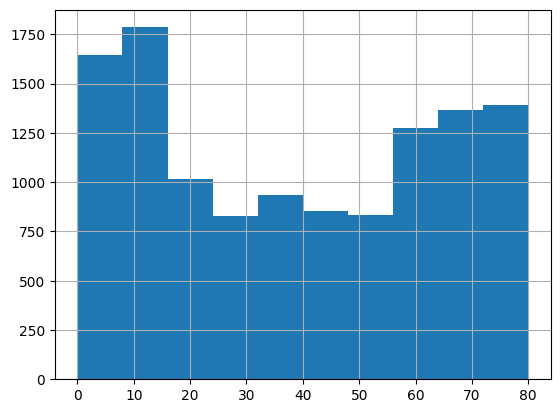

In [47]:
df['age'].hist()

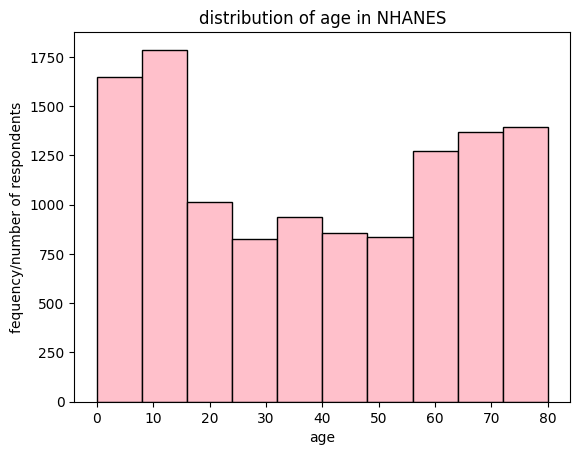

In [50]:
df['age'].hist(edgecolor = 'black', color ='pink')
plt.title('distribution of age in NHANES')
plt.ylabel('fequency/number of respondents')
plt.xlabel('age')
#to take away squares write this
plt.grid(False)
#to add color and darker edges write in the his(edgecolor, color)

Summarization and visualization of one categorical/qualitative variables

In [52]:
df['education_label'].value_counts()

,count
education_label,
college grad,2625
some college or AA degree,2370
high school grad,1749
9-11th grade,666
less than 9th grade,373
do not know,11


In [53]:
df['education_label'].value_counts(normalize=True) *100

,proportion
education_label,
college grad,33.679754
some college or AA degree,30.408006
high school grad,22.440339
9-11th grade,8.545035
less than 9th grade,4.785733
do not know,0.141134


Text(0, 0.5, 'number of respondents/frequency')

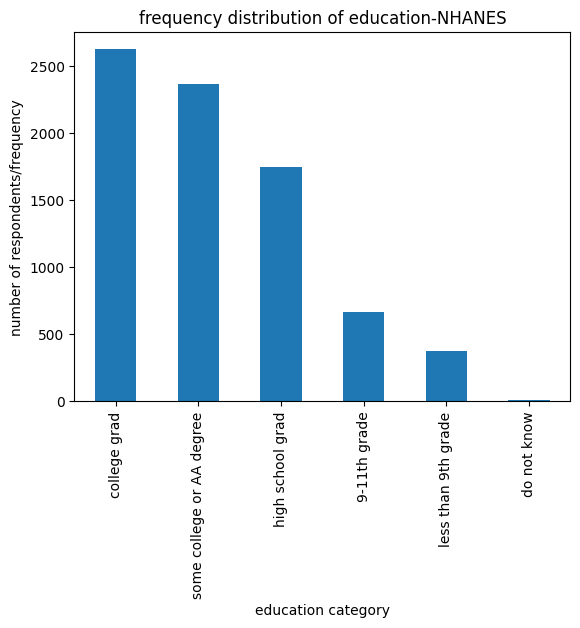

In [55]:
#visualization now
df['education_label'].value_counts().plot(kind = 'bar')
#add title
plt.title('frequency distribution of education-NHANES')
#add x axis/label
plt.xlabel('education category')
#add y axis/label
plt.ylabel('number of respondents/frequency')

2 numerical variables

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

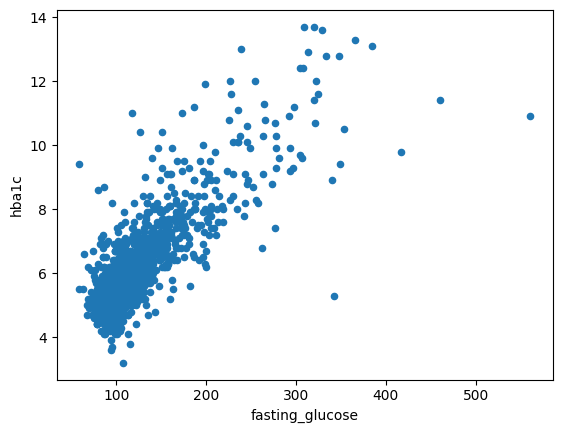

In [61]:
df.plot(x='fasting_glucose', y= 'hba1c', kind='scatter')
#remove outliers to get more clear data

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

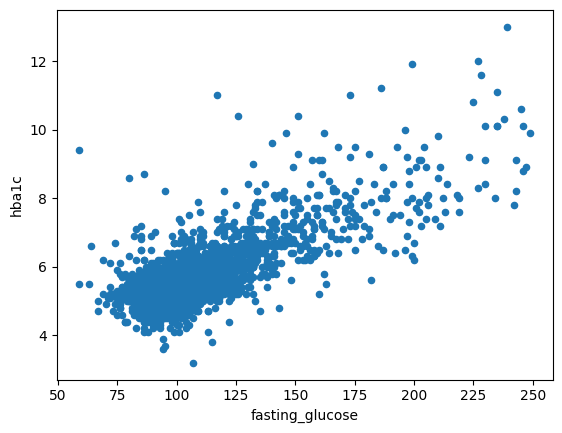

In [63]:
df_no_outliers= df[df['fasting_glucose']<250]
df_no_outliers.plot(x='fasting_glucose', y='hba1c', kind='scatter')
#make a new data frame
#make smaller number by changing <300 to <250


2 categorical values

In [65]:
#this is cuting the categories from last week to get more accurate data by using pandas
df['bmi_category']=pd.cut(df['bmi'],
                          bins=[0,18.5,25,30,100],
                          labels=['underweight','normal','overweight','obese']
                          )

In [71]:
pd.crosstab(df['bmi_category'], df['diabetes_label'], normalize='index') *100
#to be more specific switch normalize = true to normalize=index
# normalize = true is the overall population

diabetes_label,borderline,do not know,has diabetes,no diabetes
bmi_category,,,,
underweight,0.000000,0.082237,0.328947,99.588816
normal,1.625000,0.041667,4.541667,93.791667
overweight,3.197807,0.000000,10.644130,86.158063
obese,4.501125,0.000000,18.904726,76.594149


In [74]:
pd.crosstab(df['bmi_category'], df['diabetes_label'].plot(kind='bar'))

TypeError: no numeric data to plot

One Numerical and One Categorical

In [75]:
df.groupby('diabetes_label')['bmi'].mean()

,bmi
diabetes_label,
borderline,32.068559
do not know,19.250000
has diabetes,32.981412
no diabetes,26.439797


Text(0, 0.5, 'BMI')

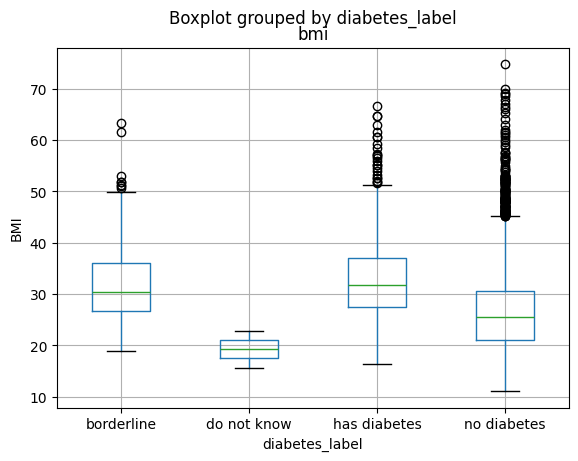

In [81]:
#boxplot
df.boxplot(column='bmi', by='diabetes_label')
#add the y label/axis
plt.ylabel('BMI')
